
# Telco Customer Churn — Exploratory Data Analysis
## 1. Introduction

### Objective

Explore customer characteristics and identify patterns
associated with customer churn.

### Analysis Overview

1. Data Preparation and Train/Test Split
2. Target Variable Analysis
3. Numerical Feature Analysis
4. Categorical Feature Analysis
5. Numerical Feature Associations
6. Multivariate Analysis
7. Business Insights and Conclusions


### Methodology

- Use an 80/20 stratified train/test split.
- Perform EDA exclusively on the training set.
- Keep the test set untouched for final evaluation.
- Extract statistical and business insights.

Model selection will later use Stratified 5-Fold
Cross-Validation on the training set.


In [18]:
from pathlib import Path
import sys

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

src_path = project_root / "src"
sys.path.insert(0, str(src_path))

import eda_utils

# Dataset path
data_path = (
    project_root / "data" / "raw"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

eda_utils.setup_plot_style()

# Figures directory
figures_dir = project_root / "reports" / "figures" / "eda"
figures_dir.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("Dataset found:", data_path.exists())
print("Figures directory:", figures_dir)


Project root: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn
Dataset found: True
Figures directory: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn\reports\figures\eda


In [19]:
df = pd.read_csv(data_path)

print(f"Number of customers: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())


Number of customers: 7,043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



## 2. Data Preparation

The initial data audit identified 11 invalid values in
`TotalCharges`, all associated with customers having
`tenure = 0`.

We convert `TotalCharges` to a numeric type and replace
these missing values with 0.



In [20]:

df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

missing_mask = df_clean["TotalCharges"].isna()

print("Missing TotalCharges:", missing_mask.sum())

assert missing_mask.sum() == 11
assert (df_clean.loc[missing_mask, "tenure"] == 0).all()

df_clean.loc[missing_mask, "TotalCharges"] = 0.0

print("Remaining missing values:", df_clean.isna().sum().sum())
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())
print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)

assert df_clean["customerID"].is_unique
assert df_clean.isna().sum().sum() == 0

Missing TotalCharges: 11
Remaining missing values: 0
Duplicate customer IDs: 0
TotalCharges dtype: float64



### 2.1 Train/Test Split

The dataset is divided into two stratified subsets:

- **Training set (80%):** Used for EDA, model training, and 5-fold cross-validation.
- **Test set (20%):** Reserved for final model evaluation.

Stratification preserves the churn distribution in both sets.

All exploratory analyses will use only the training set to avoid data leakage.


In [21]:
train_df, test_df = train_test_split(
    df_clean,
    test_size=0.20,
    stratify=df_clean["Churn"],
    random_state=42
)
eda_df = train_df.drop(columns=["customerID"]).copy()

print("Training set:", train_df.shape)
print("Test set:", test_df.shape)
print("EDA dataset:", eda_df.shape)

churn_distribution = pd.DataFrame({
    "Train (%)": train_df["Churn"].value_counts(normalize=True) * 100,
    "Test (%)": test_df["Churn"].value_counts(normalize=True) * 100
}).round(2)

display(churn_distribution)


Training set: (5634, 21)
Test set: (1409, 21)
EDA dataset: (5634, 20)


,Train (%),Test (%)
Churn,,
No,73.46,73.46
Yes,26.54,26.54



## 3. Target Variable Analysis

The target variable `Churn` indicates whether a customer has left the company.

- **No:** Customer retained.
- **Yes:** Customer churned.

We analyze the distribution of churn to identify class imbalance and understand its implications for predictive modeling.


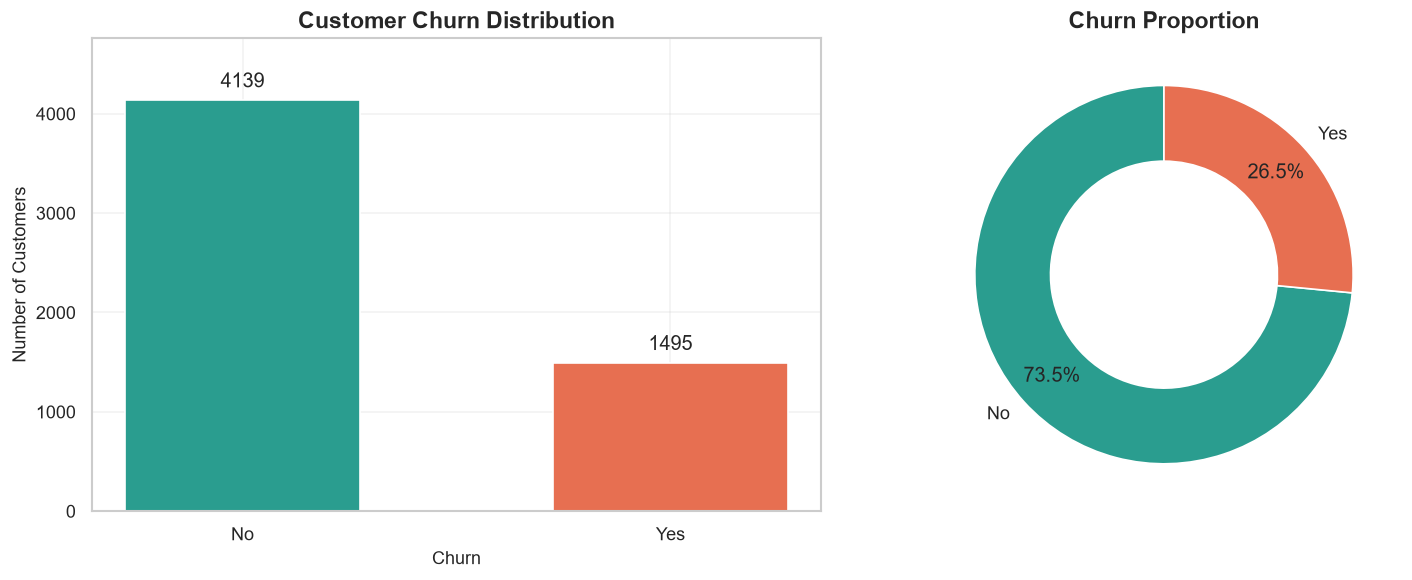

,Percentage (%)
Churn,
No,73.46
Yes,26.54


In [22]:
fig = eda_utils.plot_churn_distribution(eda_df)

fig.savefig(
    figures_dir / "01_churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

churn_summary = (
    eda_df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(churn_summary.to_frame("Percentage (%)"))



### Key Findings

- 26.5% of customers have churned.
- 73.5% of customers have remained.
- The target variable shows a moderate class imbalance.
- Model evaluation should consider precision, recall,
  F1-score, and PR-AUC rather than accuracy alone.



## 4. Numerical Feature Analysis

We examine tenure, monthly charges, and total charges
using KDE plots and boxplots to compare their
distributions across churn groups.


In [23]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]


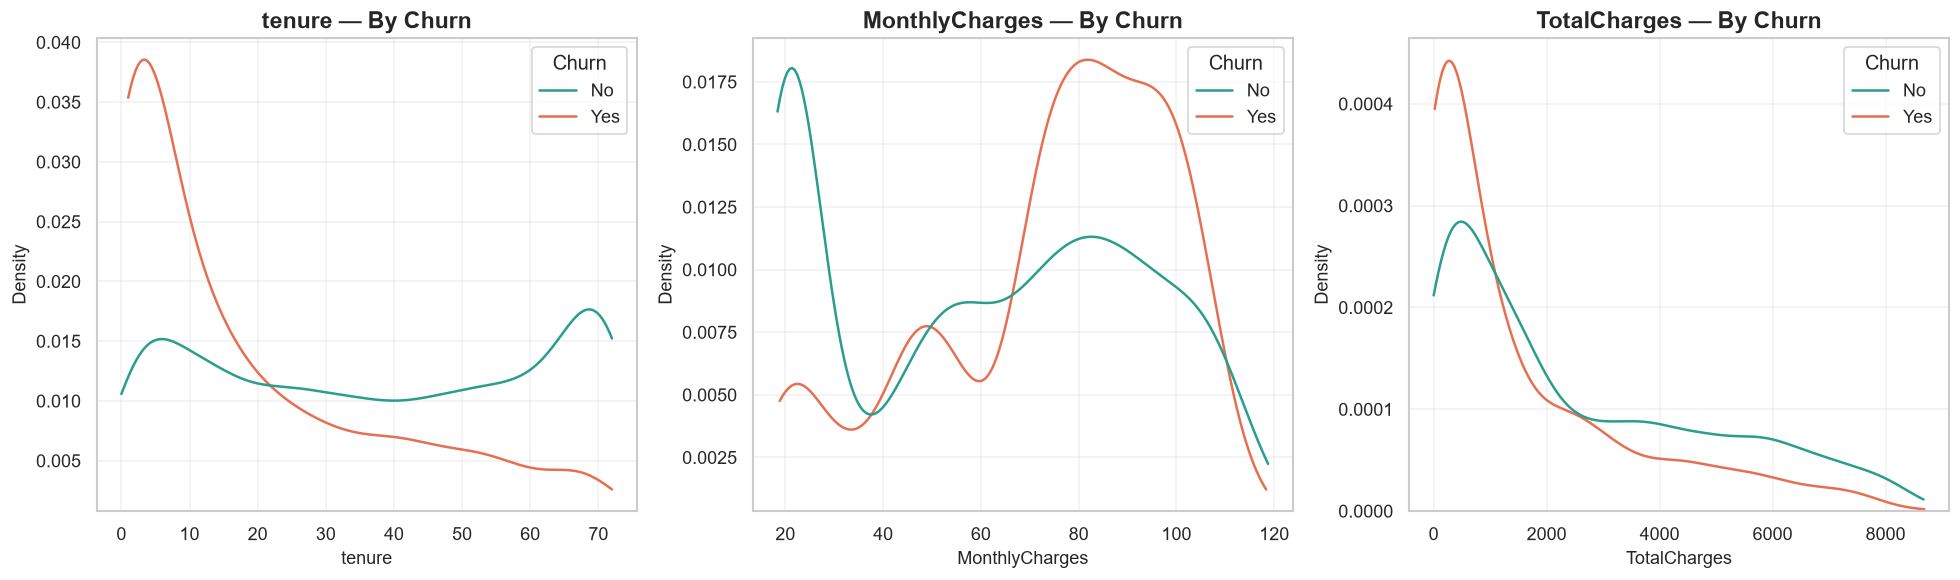

In [24]:
fig = eda_utils.plot_numerical_features(
    eda_df,
    numerical_features,
    mode="by_churn"
)
fig.savefig(
    figures_dir / "02_numerical_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 4.1 Numerical Distributions by Churn — Key Findings

- **Tenure:** Churned customers are concentrated at shorter tenures, while retained customers are more represented among long-term subscribers.
- **MonthlyCharges:** Churned customers show a higher concentration of monthly charges around $80–100, whereas retained customers have a prominent peak near $20.
- **TotalCharges:** Churned customers are concentrated at lower accumulated charges, partly reflecting their shorter tenure.

These patterns suggest associations between churn, customer tenure, and billing characteristics. Further analysis is needed to examine churn rates directly.


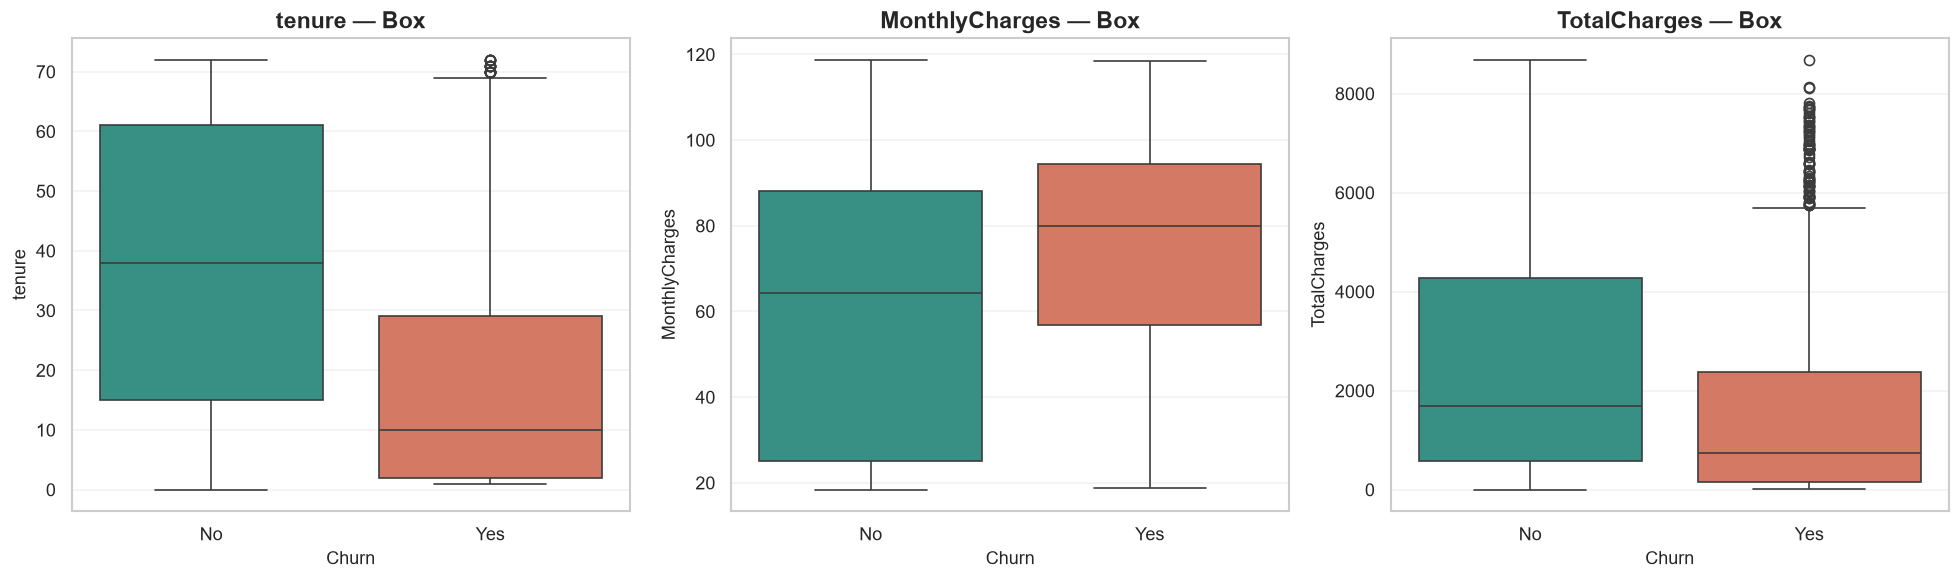

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.40,1686.15
Yes,10.0,79.95,740.30


In [25]:
fig = eda_utils.plot_numerical_features(
    eda_df,
    numerical_features,
    mode="box"
)
fig.savefig(
    figures_dir / "03_numerical_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


display(
    eda_df.groupby("Churn")[numerical_features]
    .median()
    .round(2)
)




### 4.2 Numerical Boxplots — Key Findings

- **Tenure:** Churned customers have a substantially lower median tenure (10 months) than retained customers (38 months).
- **MonthlyCharges:** Churned customers have higher median monthly charges ($79.95 vs. $64.40).
- **TotalCharges:** Retained customers have higher median accumulated charges, partly reflecting their longer tenure.
- **Outliers:** Some churned customers have high tenure and TotalCharges values. These are not necessarily data errors.

Overall, tenure and monthly charges show notable associations with churn, but these relationships do not establish causality.



## 5. Categorical Feature Analysis

We analyze categorical features related to:

- **Demographics:** Gender, senior citizen status, partner, and dependents.
- **Contracts and Billing:** Contract type, payment method, and paperless billing.
- **Services:** Internet, phone, security, technical support, and streaming services.



In [26]:

# Convert SeniorCitizen to readable labels for EDA
eda_df["SeniorCitizenLabel"] = (
    eda_df["SeniorCitizen"].map({0: "No", 1: "Yes"})
)

# Group categorical features
categorical_groups = {
    "Demographics": [
        "gender",
        "SeniorCitizenLabel",
        "Partner",
        "Dependents"
    ],

    "Contracts and Billing": [
        "Contract",
        "PaperlessBilling",
        "PaymentMethod"
    ],

    "Phone Services": [
        "PhoneService",
        "MultipleLines"
    ],

    "Internet and Additional Services": [
        "InternetService",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]
}

for group, features in categorical_groups.items():
    print(f"\n{group} ({len(features)} features)")
    print(", ".join(features))



Demographics (4 features)
gender, SeniorCitizenLabel, Partner, Dependents

Contracts and Billing (3 features)
Contract, PaperlessBilling, PaymentMethod

Phone Services (2 features)
PhoneService, MultipleLines

Internet and Additional Services (7 features)
InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies


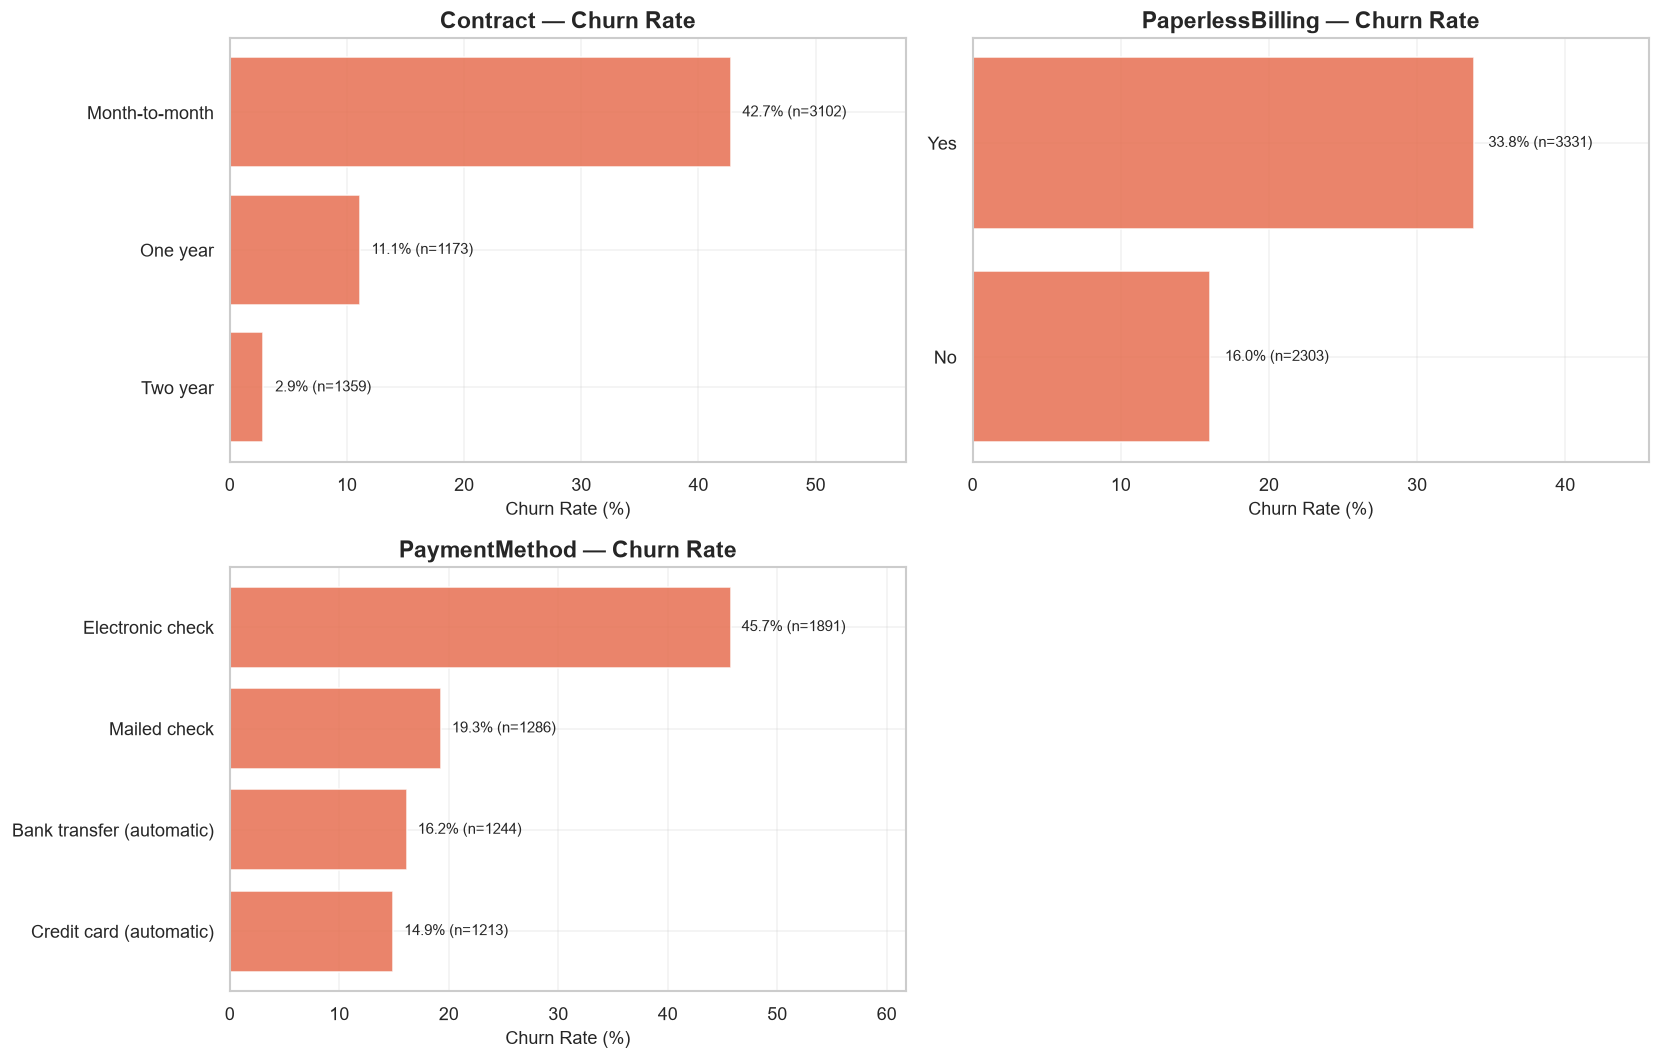

In [27]:

fig = eda_utils.plot_categorical_features(
    eda_df,
    categorical_groups["Contracts and Billing"],
    mode="rate"
)

fig.savefig(
    figures_dir / "04_contract_billing_churn_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 5.1 Contracts and Billing — Key Findings

- **Contract:** Month-to-month customers have the highest churn rate (42.7%), compared to one-year (11.1%) and two-year contracts (2.9%).
- **PaperlessBilling:** Customers using paperless billing show higher churn rates (33.8% vs. 16.0%).
- **PaymentMethod:** Electronic check users have the highest churn rate (45.7%), while automatic payment methods show lower rates (14.9–16.2%).

Contract type and payment method show strong associations with churn. Further multivariate analysis is needed to assess these relationships while accounting for other customer characteristics.



### 5.2 Categorical Feature Associations — Cramér's V

We use bias-corrected Cramér's V to measure the strength
of association between categorical features and churn.

- Values range from 0 (no association) to 1 (perfect association).
- Higher values indicate stronger associations.
- Cramér's V does not indicate direction or causality.

Features are ranked by association strength to identify
which customer characteristics deserve further analysis.


,Cramér's V
Contract,0.411
OnlineSecurity,0.351
TechSupport,0.344
InternetService,0.326
PaymentMethod,0.310
OnlineBackup,0.294
DeviceProtection,0.279
StreamingMovies,0.231
StreamingTV,0.230
PaperlessBilling,0.198


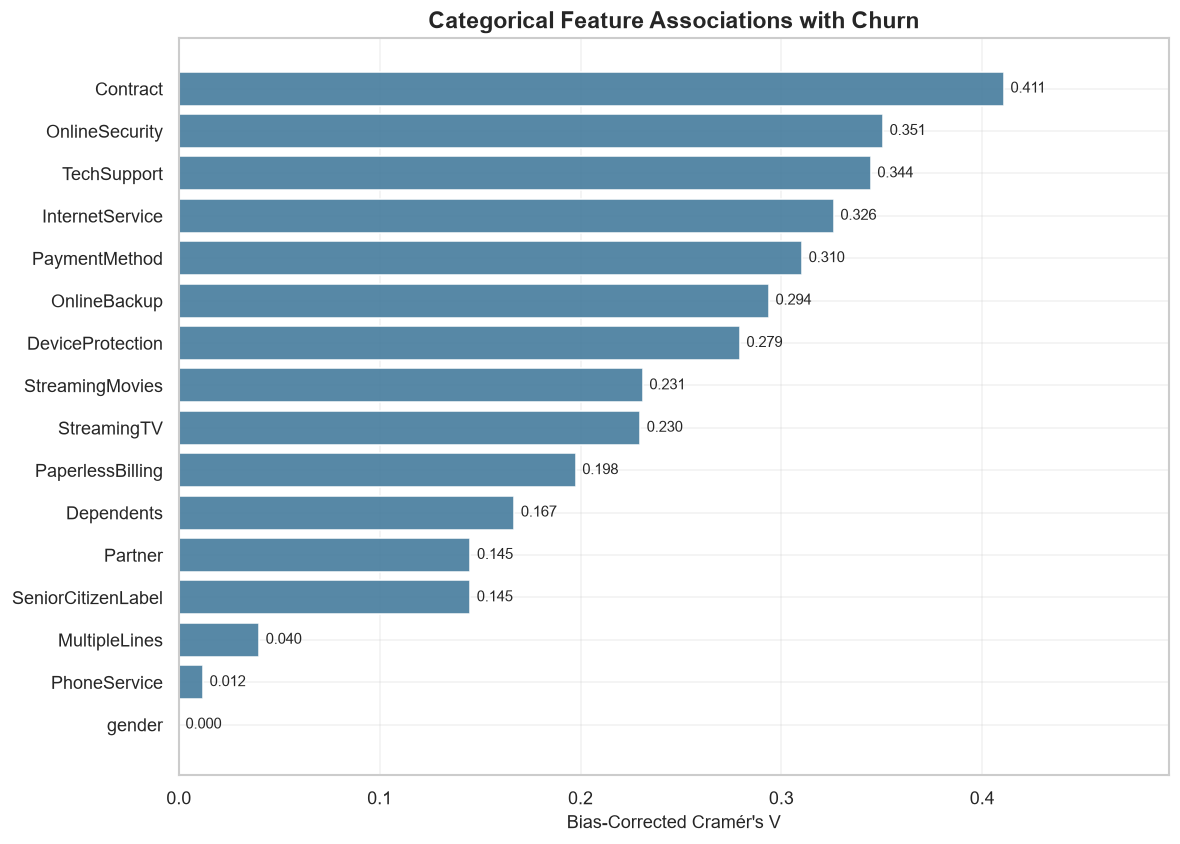

In [28]:
# Collect all categorical features
categorical_features = [
    feature
    for features in categorical_groups.values()
    for feature in features
]

# Compute bias-corrected Cramér's V
cramers_scores = pd.Series(
    {
        feature: eda_utils.compute_cramers_v(
            eda_df, feature, target="Churn"
        )
        for feature in categorical_features
    },
    name="Cramér's V"
).sort_values(ascending=False)

# Display association scores
display(cramers_scores.round(3).to_frame())

# Visualize associations
fig = eda_utils.plot_cramers_v(cramers_scores)

# Save figure
fig.savefig(
    figures_dir / "05_cramers_v_associations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 5.2.1 Cramér's V — Key Findings

- **Contract** shows the strongest association with churn (V = 0.411).
- **OnlineSecurity**, **TechSupport**, **InternetService**, and **PaymentMethod** also show notable associations (V = 0.310–0.351).
- **Gender** and **PhoneService** show negligible marginal associations with churn.

Service-related associations may partly reflect overlapping subscription characteristics.

Cramér's V measures association strength, not causality or predictive feature importance.



## 6. Numerical Feature Associations — Spearman

Spearman correlation measures monotonic relationships
between numerical features and churn.

Churn is temporarily encoded as 0 (No) and 1 (Yes).

Positive values indicate a positive association,
while negative values indicate a negative association.


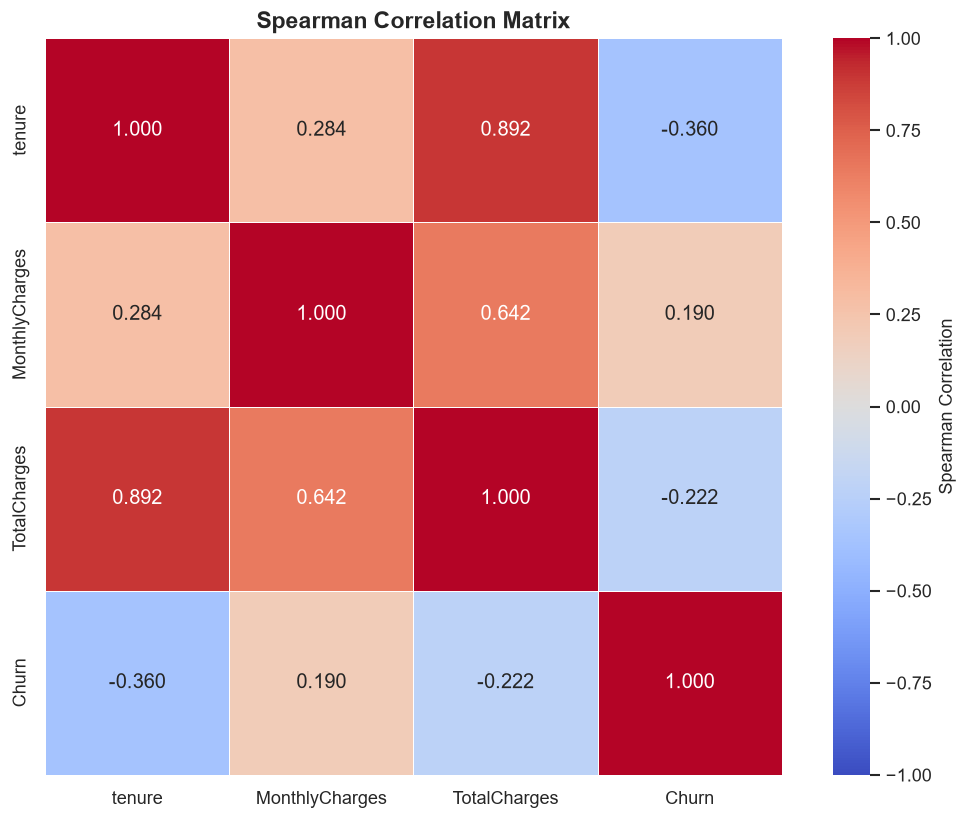

,Spearman Correlation
tenure,-0.359904
TotalCharges,-0.222448
MonthlyCharges,0.189545


In [29]:

# Create a temporary DataFrame for correlation analysis
corr_df = eda_df[numerical_features].copy()

# Encode target temporarily
corr_df["Churn"] = eda_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Compute Spearman correlation matrix
spearman_corr = corr_df.corr(method="spearman")

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman Correlation"},
    ax=ax
)

ax.set_title("Spearman Correlation Matrix")

plt.tight_layout()

# Save figure
fig.savefig(
    figures_dir / "06_spearman_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display correlations with churn
display(
    spearman_corr["Churn"]
    .drop("Churn")
    .sort_values()
    .to_frame("Spearman Correlation")
)



### 6.1 Spearman Correlation — Key Findings

- **Tenure:** Shows the strongest negative association with churn (ρ = -0.360).
- **MonthlyCharges:** Shows a weak positive association with churn (ρ = 0.190).
- **TotalCharges:** Shows a negative association with churn (ρ = -0.222).

A strong correlation exists between tenure and TotalCharges (ρ = 0.892), suggesting potential feature redundancy.

These findings support further investigation of numerical features during modeling.



## 7. Multivariate Analysis

We investigate how combinations of customer characteristics relate to churn.

The analysis focuses on:

- **Contract × Tenure:** Customer loyalty across contract types.
- **Contract × InternetService:** Churn patterns across subscription profiles.
- **OnlineSecurity × TechSupport:** Churn patterns associated with additional services.

In [30]:

# Create customer tenure groups
tenure_bins = [-1, 12, 24, 36, 48, 60, 72]

tenure_labels = [
    "0-12",
    "13-24",
    "25-36",
    "37-48",
    "49-60",
    "61-72"
]

eda_df["tenure_group"] = pd.cut(
    eda_df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

assert eda_df["tenure_group"].notna().all()

display(
    eda_df["tenure_group"]
    .value_counts()
    .sort_index()
    .to_frame("Customer Count")
)


,Customer Count
tenure_group,
0-12,1737
13-24,818
25-36,669
37-48,621
49-60,658
61-72,1131


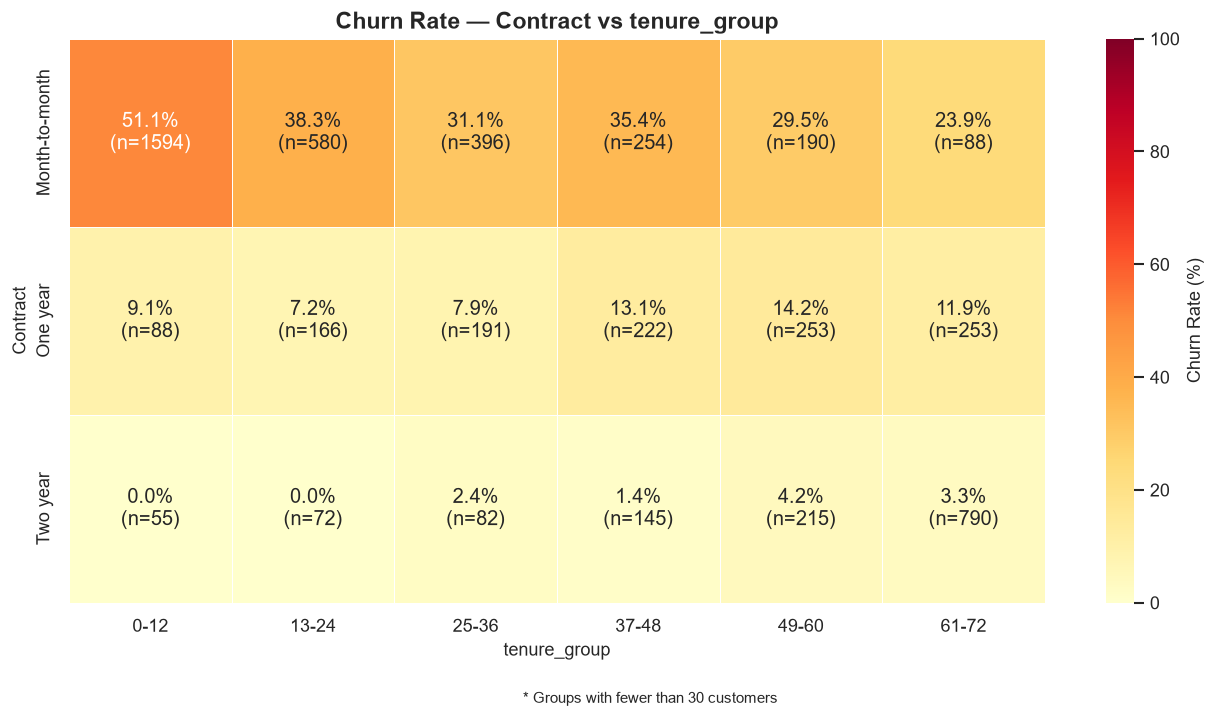

In [31]:
# Plot churn rates by contract and tenure group
fig = eda_utils.plot_churn_heatmap(
    eda_df,
    row_feature="Contract",
    col_feature="tenure_group",
    target="Churn",
    min_count=30
)

fig.savefig(
    figures_dir / "07_contract_tenure_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 7.1 Contract × Tenure — Key Findings

- **Month-to-month:** Churn is highest among new customers (51.1%) and generally decreases with tenure.
- **One-year:** Churn rates remain substantially lower across tenure groups (7.2–14.2%).
- **Two-year:** Churn rates are consistently low (0–4.2%).

Contract type remains strongly associated with churn across different tenure groups.

These findings highlight newer customers with month-to-month contracts as a potential priority segment for retention analysis.


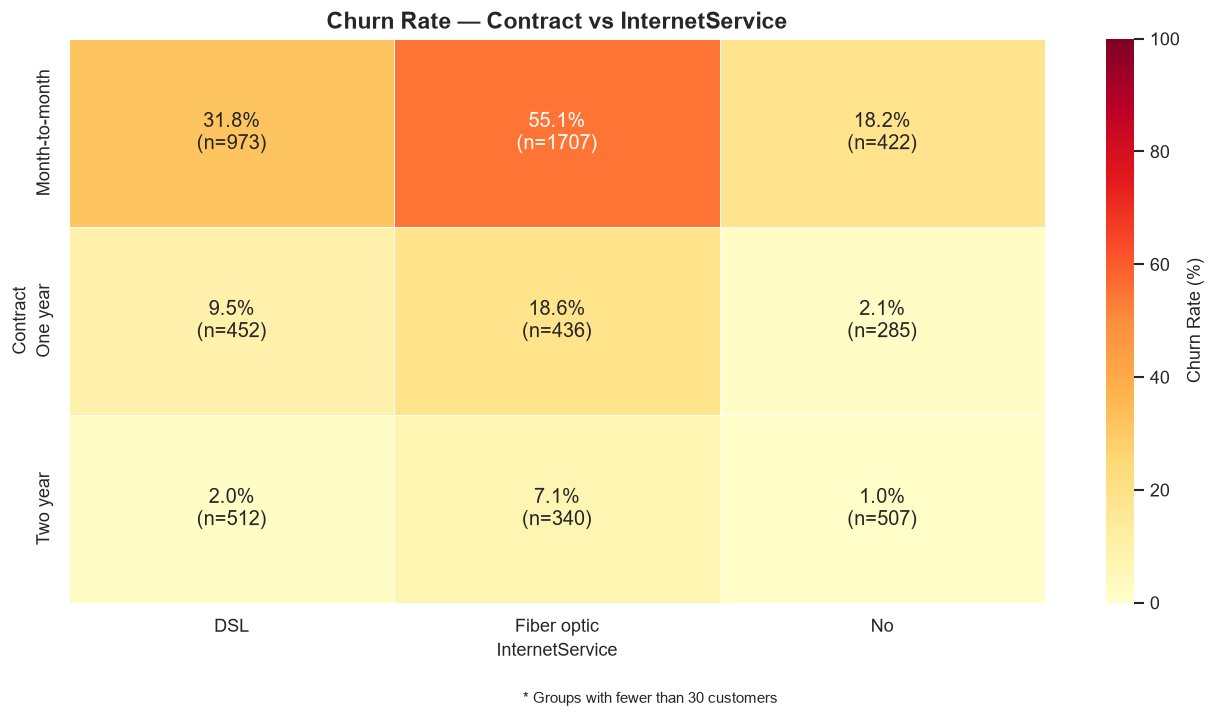

In [32]:

# Plot churn rates by contract and internet service
fig = eda_utils.plot_churn_heatmap(
    eda_df,
    row_feature="Contract",
    col_feature="InternetService",
    target="Churn",
    min_count=30
)

fig.savefig(
    figures_dir / "08_contract_internet_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 7.2 Contract × InternetService — Key Findings

- **Month-to-month contracts** show the highest churn rates across all internet service types.
- **Fiber optic customers** consistently show higher churn rates than DSL customers within each contract category.
- **Highest-risk segment:** Fiber optic customers with month-to-month contracts (55.1%, n=1,707).
- **Two-year contracts** show relatively low churn rates across all internet service types (1.0–7.1%).

The combination of fiber optic service and month-to-month contracts represents a potential priority segment for retention analysis.


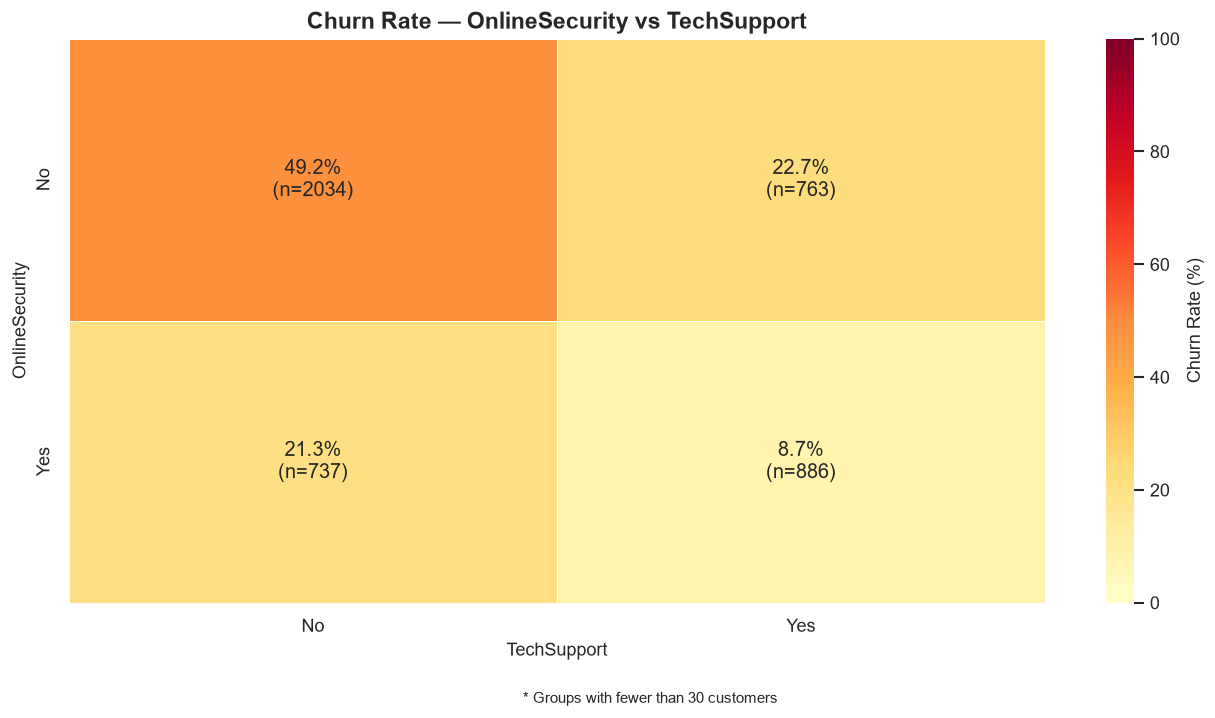

In [33]:

# Select customers with an Internet subscription
internet_df = eda_df.loc[
    eda_df["InternetService"] != "No"
].copy()

# Plot churn rates by OnlineSecurity and TechSupport
fig = eda_utils.plot_churn_heatmap(
    internet_df,
    row_feature="OnlineSecurity",
    col_feature="TechSupport",
    target="Churn",
    min_count=30
)

fig.savefig(
    figures_dir / "09_security_support_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 7.3 OnlineSecurity × TechSupport — Key Findings

- **Neither service:** Customers without both services show the highest churn rate (49.2%).
- **One service:** Churn rates range from 21.3% to 22.7%.
- **Both services:** Customers with both services show the lowest churn rate (8.7%).

The absence of both services is associated with substantially higher churn.

These relationships may also reflect differences in contract type, tenure, or customer profiles.



## 8. Business Insights & Conclusions

### 8.1 Key Findings

- **Customer Tenure:** New customers are more strongly associated with churn than long-term subscribers.
- **Contract Type:** Month-to-month contracts show substantially higher churn rates (42.7%) than two-year contracts (2.9%).
- **Monthly Charges:** Higher monthly charges are positively associated with churn.
- **Internet Service:** Fiber optic customers show higher churn rates than DSL customers across contract types.
- **Additional Services:** Customers without OnlineSecurity and TechSupport show higher churn rates.

### 8.2 High-Risk Customer Segments

The analysis highlights three customer segments with elevated churn rates:

- **Fiber optic + Month-to-month:** 55.1% churn.
- **Month-to-month + 0–12 months tenure:** 51.1% churn.
- **No OnlineSecurity + No TechSupport:** 49.2% churn among Internet subscribers.

These segments may warrant further investigation and targeted retention strategies.

### 8.3 Business Recommendations

- Investigate early customer churn and onboarding experiences.
- Explore retention incentives for month-to-month subscribers.
- Examine customer satisfaction and pricing among fiber optic users.
- Evaluate whether additional support and security services contribute to customer retention.


### 8.4 Machine Learning Implications


- **Class Imbalance:** Compare standard training, class weighting, and random oversampling within stratified cross-validation. Evaluate models using precision, recall, F1-score, ROC-AUC, and PR-AUC.
- **Categorical Features:** Apply appropriate encoding within preprocessing pipelines.
- **Numerical Features:** Apply scaling when required by the model.
- **Multicollinearity:** The strong correlation between tenure and TotalCharges (ρ = 0.892) suggests potential feature redundancy.
- **Regularization:** Compare L1 and L2 regularization in Logistic Regression to manage correlated features.
- **Tree-Based Models:** Evaluate Random Forest and XGBoost, which are generally less sensitive to multicollinearity for prediction.
- **Threshold Optimization:** Optimize the classification threshold using training data only.


### 8.5 Limitations

The findings represent statistical associations, not causal relationships.

Customer characteristics may be correlated, and the identified segments may overlap.

Further modeling and validation are required before making operational retention decisions.
